# group project
## Student performance: Spark scalability

Option A. I reused my [student performance project](https://github.com/timwalewangko/personal_porfolio/blob/main/Kaggle%20Analysis/student-success-factors/student-success-factors.ipynb).
The [Kaggle dataset](https://www.kaggle.com/datasets/ayeshasiddiqa123/student-perfirmance) has 6,607 rows and 20 columns describing studying, attendance, student background, and exam scores.

I reused the cleaning and preprocessing from that project in PySpark: missing values, string cleanup, score capping, one-hot encoding, and scaling. I added a study/attendance interaction, a join with group averages, and grouped summaries. The workload ends with processed Parquet files and summary statistics.

These experiments use separate Spark worker processes on one laptop. They share the same CPU, RAM, and SSD. The rubric requires Dataproc, so this local version needs instructor approval for submission.

## 1. Setup

Run from the repository root. Create a Python environment here with `python3 -m venv .venv`, install with `.venv/bin/pip install -r requirements.txt`, and select it as the notebook kernel. Java 17 is the same as HW4. Run from top to bottom; the cluster starts and stops automatically.

Experiment I: 100 MB, 500 MB, 1 GB, and 2 GB with 2 workers.
Experiment II: the same 500 MB dataset with 1, 2, and 5 workers.
Each worker gets one executor, 2 task slots, and a 1.5 GiB heap. Each configuration runs three times. Results use the median and a one-worker baseline.

AQE and constraint propagation are disabled throughout.

In [ ]:
import os
import sys
import json
import math
import time
import random
import platform
import subprocess
from pathlib import Path
from urllib.request import urlopen
from urllib.parse import urlparse

os.environ["JAVA_HOME"] = (
    "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"
)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 2g pyspark-shell"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyspark
from IPython.display import display, Markdown
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark import StorageLevel

BASE = Path.cwd()
DATA = BASE / "data"
RESULTS = BASE / "results"
PROCESSED = BASE / "processed"
RUNTIME = BASE / ".spark"
for folder in [DATA, RESULTS, PROCESSED, RUNTIME]:
    folder.mkdir(exist_ok=True)

SPARK_HOME = Path(pyspark.__file__).parent
os.environ["SPARK_LOCAL_DIRS"] = str(RUNTIME / "tmp")
os.environ["SPARK_DAEMON_MEMORY"] = "256m"
PARTITIONS = 64

In [ ]:
def launch(name, args, logfile):
    log = open(RUNTIME / logfile, "w")
    return subprocess.Popen(
        [str(SPARK_HOME / "bin/spark-class"), name, *args],
        stdout=log,
        stderr=subprocess.STDOUT,
        env=os.environ.copy(),
    )


def start_cluster(workers):
    master = launch(
        "org.apache.spark.deploy.master.Master",
        ["--host", "127.0.0.1", "--port", "7090", "--webui-port", "8090"],
        "master.log",
    )
    time.sleep(4)
    processes = [master]
    for i in range(workers):
        processes.append(
            launch(
                "org.apache.spark.deploy.worker.Worker",
                [
                    "--host",
                    "127.0.0.1",
                    "--port",
                    str(7091 + i),
                    "--webui-port",
                    str(8091 + i),
                    "--cores",
                    "2",
                    "--memory",
                    "1536m",
                    "--work-dir",
                    str(RUNTIME / f"worker-{i}"),
                    "spark://127.0.0.1:7090",
                ],
                f"worker-{i}.log",
            )
        )
    time.sleep(4)
    spark = (
        SparkSession.builder.master("spark://127.0.0.1:7090")
        .appName(f"hw5-{workers}-workers")
        .config("spark.driver.host", "127.0.0.1")
        .config("spark.driver.bindAddress", "127.0.0.1")
        .config("spark.executor.instances", str(workers))
        .config("spark.executor.cores", "2")
        .config("spark.executor.memory", "1536m")
        .config("spark.cores.max", str(workers * 2))
        .config("spark.dynamicAllocation.enabled", "false")
        .config("spark.sql.shuffle.partitions", str(PARTITIONS))
        .config("spark.sql.adaptive.enabled", "false")
        .config("spark.sql.constraintPropagation.enabled", "false")
        .config("spark.ui.showConsoleProgress", "false")
        .config("spark.sql.files.maxPartitionBytes", str(32 * 1024**2))
        .config("spark.memory.fraction", "0.4")
        .config("spark.sql.files.minPartitionNum", "2")
        .config("spark.ui.retainedStages", "10000")
        .config("spark.eventLog.enabled", "true")
        .config("spark.eventLog.dir", (RUNTIME / "events").as_uri())
        .getOrCreate()
    )
    spark.sparkContext.setLogLevel("ERROR")
    return spark, processes


def stop_cluster(spark, processes):
    spark.stop()
    for process in reversed(processes):
        process.terminate()
        process.wait()


(RUNTIME / "events").mkdir(exist_ok=True)

## 2. Multiply the dataset

Only the original rows are repeated; no random rows or padding. Duplicates in the source are removed once before multiplication, so intentional repetitions remain. Each size is saved as uncompressed CSV, with about 100 MB per file. MB means 1,000,000 bytes. The table records actual CSV bytes, including headers.

Generating files is outside the timing. All cleaning after this point is part of the measured workload.

In [ ]:
columns = [
    "hours_studied",
    "attendance",
    "parental_involvement",
    "access_to_resources",
    "extracurricular_activities",
    "sleep_hours",
    "previous_scores",
    "motivation_level",
    "internet_access",
    "tutoring_sessions",
    "family_income",
    "teacher_quality",
    "school_type",
    "peer_influence",
    "physical_activity",
    "learning_disabilities",
    "parental_education_level",
    "distance_from_home",
    "gender",
    "exam_score",
]
numeric = [
    "hours_studied",
    "attendance",
    "sleep_hours",
    "previous_scores",
    "tutoring_sessions",
    "physical_activity",
]
categorical = [c for c in columns if c not in numeric + ["exam_score"]]
schema = T.StructType(
    [
        T.StructField(
            c, T.IntegerType() if c in numeric + ["exam_score"] else T.StringType()
        )
        for c in columns
    ]
)

spark, processes = start_cluster(2)
seed = (
    spark.read.option("header", True)
    .schema(schema)
    .csv(str(BASE / "StudentPerformanceFactors.csv"))
    .dropDuplicates()
)
seed.coalesce(1).write.mode("overwrite").option("header", True).csv(str(DATA / "seed"))
seed_rows = seed.count()
seed_bytes = sum(p.stat().st_size for p in (DATA / "seed").glob("part-*.csv"))
manifest = []
for mb in [100, 500, 1000, 2000]:
    copies = math.ceil(mb * 1_000_000 / seed_bytes)
    files = math.ceil(mb / 100)
    expanded = (
        spark.range(copies, numPartitions=files)
        .crossJoin(F.broadcast(seed))
        .select(*columns)
    )
    path = DATA / f"{mb}mb"
    expanded.write.mode("overwrite").option("header", True).csv(str(path))
    size = sum(p.stat().st_size for p in path.glob("part-*.csv"))
    manifest.append(
        dict(
            size_mb=mb,
            actual_mb=size / 1_000_000,
            rows=seed_rows * copies,
            copies=copies,
            files=files,
        )
    )
sizes = pd.DataFrame(manifest)
sizes.to_csv(RESULTS / "dataset_sizes.csv", index=False)
display(sizes.round(3))
stop_cluster(spark, processes)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 21:50:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


,size_mb,actual_mb,rows,copies,files
0,100,100.332,1043906,158,1
1,500,499.755,5199709,787,5
2,1000,999.509,10399418,1574,10
3,2000,1999.018,20798836,3148,20


## 3. PySpark preprocessing

The same cleaning as the old project: lowercase names, trim/title-case strings, drop missing rows, cast numbers, and cap scores at 100. The cap flag is kept for checking.

Categories are hardcoded from this dataset. Numeric columns are standardized using Spark averages and population standard deviations. Added features are study hours × attendance, log tutoring sessions, and previous score minus the average for the same school/resource group.

In [ ]:
def clean(spark, path):
    df = spark.read.option("header", True).schema(schema).csv(str(path))
    for c in categorical:
        df = df.withColumn(c, F.initcap(F.trim(F.col(c))))
    for c in numeric + ["exam_score"]:
        df = df.withColumn(c, F.col(c).cast("double"))
    df = df.dropna()
    return (
        df.withColumn("score_capped", (F.col("exam_score") > 100).cast("int"))
        .withColumn("exam_score", F.least(F.col("exam_score"), F.lit(100.0)))
        .withColumn(
            "study_attendance", F.col("hours_studied") * F.col("attendance") / 100
        )
        .withColumn("log_tutoring", F.log1p("tutoring_sessions"))
    )


levels = {
    "parental_involvement": ["Low", "Medium", "High"],
    "access_to_resources": ["Low", "Medium", "High"],
    "extracurricular_activities": ["No", "Yes"],
    "motivation_level": ["Low", "Medium", "High"],
    "internet_access": ["No", "Yes"],
    "family_income": ["Low", "Medium", "High"],
    "teacher_quality": ["Low", "Medium", "High"],
    "school_type": ["Private", "Public"],
    "peer_influence": ["Negative", "Neutral", "Positive"],
    "learning_disabilities": ["No", "Yes"],
    "parental_education_level": ["High School", "College", "Postgraduate"],
    "distance_from_home": ["Near", "Moderate", "Far"],
    "gender": ["Female", "Male"],
}
scaled = numeric + ["study_attendance", "log_tutoring", "previous_score_gap"]
flags = [
    (c, value, c + "_" + value.lower().replace(" ", "_"))
    for c, values in levels.items()
    for value in values
]
features = [c + "_z" for c in scaled] + [name for c, value, name in flags]


def prepare(spark, path):
    df = clean(spark, path)
    group_means = df.groupBy("school_type", "access_to_resources").agg(
        F.avg("previous_scores").alias("group_previous_score")
    )
    df = (
        df.join(F.broadcast(group_means), ["school_type", "access_to_resources"])
        .withColumn(
            "previous_score_gap",
            F.col("previous_scores") - F.col("group_previous_score"),
        )
        .persist(StorageLevel.MEMORY_AND_DISK)
    )
    stats = (
        df.agg(
            *[
                expr
                for c in scaled
                for expr in [
                    F.avg(c).alias(c + "_mean"),
                    F.stddev_pop(c).alias(c + "_std"),
                ]
            ]
        )
        .first()
        .asDict()
    )
    normalized = [
        ((F.col(c) - stats[c + "_mean"]) / stats[c + "_std"]).alias(c + "_z")
        for c in scaled
    ]
    encoded = [
        (F.col(c) == value).cast("double").alias(name) for c, value, name in flags
    ]
    return df.select("*", *normalized, *encoded), df


def materialize(spark, prepared, path):
    (
        prepared.repartition(PARTITIONS)
        .write.mode("overwrite")
        .option("compression", "snappy")
        .parquet(str(path))
    )
    output = spark.read.parquet(str(path))
    energy = sum((i + 1) * F.col(c) * F.col(c) for i, c in enumerate(features))
    return (
        output.groupBy("school_type", "access_to_resources")
        .agg(
            F.count("*").alias("rows"),
            F.sum("exam_score").alias("score_sum"),
            F.sum("score_capped").alias("capped"),
            F.sum(energy).alias("feature_sum"),
            F.avg("hours_studied").alias("mean_hours"),
        )
        .orderBy("school_type", "access_to_resources")
        .collect()
    )

## 4. Timing

Timing includes CSV loading, cleaning, groupBy/join, normalization statistics, encoding, repartitioning, writing Snappy Parquet, and reading it back for grouped summaries. The joined table is cached within each trial. Timing ends after collecting the six summary rows. Writing the processed data forces every output column to be computed.

File generation, cluster startup, diagnostics, final cache removal, and saving timing tables are excluded. Spark caches are cleared between trials; OS file caches are not. These are warmed local runs. Throughput is input MB / total seconds, not physical disk bandwidth.

In [ ]:
def ui(spark, endpoint):
    sc = spark.sparkContext
    port = urlparse(sc.uiWebUrl).port
    url = f"http://127.0.0.1:{port}/api/v1/applications/{sc.applicationId}/{endpoint}"
    with urlopen(url) as response:
        return json.load(response)


def stage_totals(spark):
    stages = ui(spark, "stages?status=complete")
    keys = [
        "numTasks",
        "executorRunTime",
        "executorCpuTime",
        "shuffleReadBytes",
        "shuffleWriteBytes",
        "diskBytesSpilled",
    ]
    return {k: sum(s[k] for s in stages) for k in keys}


def benchmark(spark, workers, mb, trial):
    spark.catalog.clearCache()
    before = stage_totals(spark)
    spark.sparkContext.setJobGroup(
        f"w{workers}-{mb}mb-trial{trial}", "student performance"
    )
    start = time.perf_counter()
    prepared, cached = prepare(spark, DATA / f"{mb}mb")
    ready = time.perf_counter()
    path = PROCESSED / f"w{workers}-{mb}mb"
    groups = materialize(spark, prepared, path)
    end = time.perf_counter()
    after = stage_totals(spark)
    delta = {k: after[k] - before[k] for k in before}
    cached.unpersist(blocking=True)
    rows = sum(g.rows for g in groups)
    actual_mb = float(sizes.set_index("size_mb").loc[mb, "actual_mb"])
    return dict(
        workers=workers,
        task_slots=workers * 2,
        size_mb=mb,
        actual_mb=actual_mb,
        trial=trial,
        rows=rows,
        groups=len(groups),
        partitions=PARTITIONS,
        statistics_s=ready - start,
        output_s=end - ready,
        seconds=end - start,
        mb_s=actual_mb / (end - start),
        mean_score=sum(g.score_sum for g in groups) / rows,
        feature_checksum=sum(g.feature_sum for g in groups) / rows,
        capped_rows=sum(g.capped for g in groups),
        output_mb=sum(p.stat().st_size for p in path.glob("part-*.parquet")) / 1e6,
        tasks=delta["numTasks"],
        task_seconds=delta["executorRunTime"] / 1000,
        task_cpu_seconds=delta["executorCpuTime"] / 1e9,
        shuffle_read_mb=delta["shuffleReadBytes"] / 1e6,
        shuffle_write_mb=delta["shuffleWriteBytes"] / 1e6,
        disk_spill_mb=delta["diskBytesSpilled"] / 1e6,
        spark_version=spark.version,
        application_id=spark.sparkContext.applicationId,
    )

## 5. Correctness check

First check the small source dataset. Each larger dataset should have the source row count times its copy count. Mean exam score and the feature checksum should stay the same because only rows are repeated. The checksum uses all normalized and one-hot columns.

In [ ]:
spark, processes = start_cluster(2)
source = clean(spark, DATA / "seed")
source.groupBy("access_to_resources").agg(
    F.count("*").alias("rows"), F.avg("exam_score").alias("mean_score")
).orderBy("access_to_resources").show()
source.select(
    F.max("exam_score").alias("max_score"), F.sum("score_capped").alias("capped_rows")
).show()
assert source.agg(F.max("exam_score")).first()[0] <= 100
prepared, cached = prepare(spark, DATA / "seed")
reference = materialize(spark, prepared, PROCESSED / "source")
cached.unpersist(blocking=True)
source_rows = sum(g.rows for g in reference)
source_mean = sum(g.score_sum for g in reference) / source_rows
source_checksum = sum(g.feature_sum for g in reference) / source_rows
pd.DataFrame([g.asDict() for g in reference]).to_csv(
    RESULTS / "source_summary.csv", index=False
)
display(pd.DataFrame([g.asDict() for g in reference]).round(3))
print("Clean source rows:", source_rows)

+-------------------+----+-----------------+
|access_to_resources|rows|       mean_score|
+-------------------+----+-----------------+
|               High|1900|68.10315789473684|
|                Low|1274|66.22370486656202|
|             Medium|3204|67.15605493133583|
+-------------------+----+-----------------+

+---------+-----------+
|max_score|capped_rows|
+---------+-----------+
|    100.0|          1|
+---------+-----------+



,school_type,access_to_resources,rows,score_sum,capped,feature_sum,mean_hours
0,Private,High,625,42502.0,0,246875.630,19.907
1,Private,Low,381,25277.0,0,148984.749,20.157
2,Private,Medium,938,63084.0,0,368906.823,19.929
3,Public,High,1275,86894.0,0,502329.095,20.071
4,Public,Low,893,59092.0,0,349093.202,20.097
5,Public,Medium,2266,152084.0,1,892767.501,19.886


Clean source rows: 6378


## 6. Experiment I: data scalability

Fixed at 2 workers, 4 task slots, and 64 prepared-data/shuffle partitions. Input splitting uses the same 32 MiB limit throughout; actual input partitions are recorded separately. Spark memory fraction is 0.4. One source-sized warm-up is excluded. Size order is shuffled within each trial.

Plots use medians; error bars show the minimum and maximum of the three trials.

In [ ]:
executors = [e for e in ui(spark, "executors") if e["id"] != "driver" and e["isActive"]]
assert len(executors) == 2
display(pd.DataFrame(executors)[["id", "hostPort", "totalCores", "maxMemory"]])

data_runs = []
for trial in [1, 2, 3]:
    for mb in random.Random(43 + trial).sample([100, 500, 1000, 2000], 4):
        result = benchmark(spark, 2, mb, trial)
        result["input_partitions"] = (
            spark.read.schema(schema).csv(str(DATA / f"{mb}mb")).rdd.getNumPartitions()
        )
        data_runs.append(result)
        pd.DataFrame(data_runs).to_csv(RESULTS / "data_trials.csv", index=False)
        print(f"Trial {trial}, {mb} MB: {result['seconds']:.2f} s", flush=True)
stop_cluster(spark, processes)

,id,hostPort,totalCores,maxMemory
0,1,127.0.0.1:54344,2,518415974
1,0,127.0.0.1:54343,2,518415974


Trial 1, 2000 MB: 76.78 s


Trial 1, 1000 MB: 38.84 s


Trial 1, 100 MB: 6.06 s


Trial 1, 500 MB: 20.07 s


Trial 2, 1000 MB: 38.03 s


... (3 outputs left out)

Trial 3, 100 MB: 5.44 s


Trial 3, 500 MB: 19.81 s


Trial 3, 2000 MB: 73.46 s


Trial 3, 1000 MB: 38.35 s


In [ ]:
raw_data = pd.read_csv(RESULTS / "data_trials.csv")
display(
    raw_data[
        [
            "size_mb",
            "trial",
            "rows",
            "input_partitions",
            "partitions",
            "statistics_s",
            "output_s",
            "seconds",
            "mb_s",
            "mean_score",
        ]
    ].round(3)
)
data_summary = raw_data.groupby("size_mb").agg(
    actual_mb=("actual_mb", "first"),
    rows=("rows", "first"),
    seconds=("seconds", "median"),
    min_s=("seconds", "min"),
    max_s=("seconds", "max"),
    statistics_s=("statistics_s", "median"),
    output_s=("output_s", "median"),
    output_mb=("output_mb", "median"),
    shuffle_mb=("shuffle_read_mb", "median"),
    spill_mb=("disk_spill_mb", "median"),
)
data_summary["mb_s"] = data_summary.actual_mb / data_summary.seconds
display(data_summary.round(3))
data_summary.to_csv(RESULTS / "data_summary.csv")

,size_mb,trial,rows,input_partitions,partitions,statistics_s,output_s,seconds,mb_s,mean_score
0,2000,1,20077944,60,64,40.436,36.349,76.785,26.034,67.252
1,1000,1,10038972,30,64,20.447,18.398,38.844,25.731,67.252
2,100,1,1007724,3,64,2.940,3.123,6.063,16.548,67.252
3,500,1,5019486,15,64,10.411,9.659,20.071,24.900,67.252
4,1000,2,10038972,30,64,19.907,18.121,38.029,26.283,67.252
5,500,2,5019486,15,64,10.350,9.653,20.003,24.984,67.252
6,2000,2,20077944,60,64,38.502,34.658,73.161,27.324,67.252
7,100,2,1007724,3,64,2.832,2.849,5.681,17.660,67.252
8,100,3,1007724,3,64,2.765,2.679,5.444,18.430,67.252
9,500,3,5019486,15,64,10.326,9.486,19.812,25.225,67.252


,actual_mb,rows,seconds,min_s,max_s,statistics_s,output_s,output_mb,shuffle_mb,spill_mb,mb_s
size_mb,,,,,,,,,,,
100,100.332,1007724,5.681,5.444,6.063,2.832,2.849,23.907,202.759,5.503,17.660
500,499.755,5019486,20.003,19.812,20.071,10.350,9.653,109.343,1008.242,67.968,24.984
1000,999.509,10038972,38.345,38.029,38.844,20.276,18.121,215.078,2019.978,113.157,26.066
2000,1999.018,20077944,73.464,73.161,76.785,38.647,34.817,428.946,4036.244,218.338,27.211


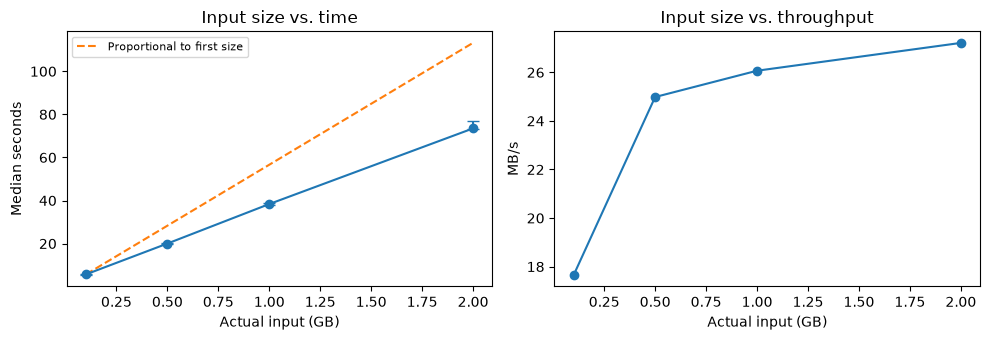

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
x = data_summary.actual_mb / 1000
y = data_summary.seconds
axes[0].errorbar(
    x, y, yerr=[y - data_summary.min_s, data_summary.max_s - y], fmt="o-", capsize=4
)
axes[0].plot(x, y.iloc[0] * x / x.iloc[0], "--", label="Proportional to first size")
axes[0].set(
    xlabel="Actual input (GB)", ylabel="Median seconds", title="Input size vs. time"
)
axes[0].legend(fontsize=8)
axes[1].plot(x, data_summary.mb_s, "o-")
axes[1].set(
    xlabel="Actual input (GB)", ylabel="MB/s", title="Input size vs. throughput"
)
fig.tight_layout()
fig.savefig(RESULTS / "data_scalability.png", dpi=160)
plt.show()

## 7. Experiment II: worker scalability

The exact same 500 MB files and application are used. This is about 5 million cleaned rows and keeps repeated local runs practical. The rubric prefers 2 GB but allows another fixed size. Each worker configuration starts in a fresh Spark application with the same source-sized warm-up. The configurations run in order 1, 5, 2. Only worker/executor count and total task slots change. Startup and warm-up are excluded.

Speedup = T₁ / Tₙ. Relative efficiency = speedup / workers × 100%. The baseline is one worker process with 2 task slots.

In [ ]:
worker_runs = []
for workers in [1, 5, 2]:
    spark, processes = start_cluster(workers)
    prepared, cached = prepare(spark, DATA / "seed")
    materialize(spark, prepared, PROCESSED / "warmup")
    cached.unpersist(blocking=True)
    executors = [
        e for e in ui(spark, "executors") if e["id"] != "driver" and e["isActive"]
    ]
    assert len(executors) == workers
    display(pd.DataFrame(executors)[["id", "hostPort", "totalCores", "maxMemory"]])
    for trial in [1, 2, 3]:
        result = benchmark(spark, workers, 500, trial)
        result["input_partitions"] = (
            spark.read.schema(schema).csv(str(DATA / "500mb")).rdd.getNumPartitions()
        )
        worker_runs.append(result)
        pd.DataFrame(worker_runs).to_csv(RESULTS / "worker_trials.csv", index=False)
        print(
            f"{workers} workers, trial {trial}: {result['seconds']:.2f} s", flush=True
        )
    stop_cluster(spark, processes)

,id,hostPort,totalCores,maxMemory
0,0,127.0.0.1:54488,2,518415974


1 workers, trial 1: 66.10 s


1 workers, trial 2: 64.55 s


1 workers, trial 3: 64.26 s


,id,hostPort,totalCores,maxMemory
0,4,127.0.0.1:54561,2,518415974
1,3,127.0.0.1:54560,2,518415974
2,2,127.0.0.1:54559,2,518415974
3,1,127.0.0.1:54563,2,518415974
4,0,127.0.0.1:54562,2,518415974


5 workers, trial 1: 34.02 s


... (3 outputs left out)

,id,hostPort,totalCores,maxMemory
0,1,127.0.0.1:54746,2,518415974
1,0,127.0.0.1:54745,2,518415974


2 workers, trial 1: 37.52 s


2 workers, trial 2: 34.81 s


2 workers, trial 3: 33.71 s


In [ ]:
raw_workers = pd.read_csv(RESULTS / "worker_trials.csv").sort_values(
    ["workers", "trial"]
)
display(
    raw_workers[
        [
            "workers",
            "task_slots",
            "trial",
            "rows",
            "statistics_s",
            "output_s",
            "seconds",
            "mb_s",
            "mean_score",
            "feature_checksum",
        ]
    ].round(3)
)
worker_summary = raw_workers.groupby("workers").agg(
    task_slots=("task_slots", "first"),
    seconds=("seconds", "median"),
    min_s=("seconds", "min"),
    max_s=("seconds", "max"),
    statistics_s=("statistics_s", "median"),
    output_s=("output_s", "median"),
    tasks=("tasks", "median"),
    shuffle_mb=("shuffle_read_mb", "median"),
    spill_mb=("disk_spill_mb", "median"),
    task_seconds=("task_seconds", "median"),
    cpu_seconds=("task_cpu_seconds", "median"),
)
worker_summary["speedup"] = worker_summary.loc[1, "seconds"] / worker_summary.seconds
worker_summary["efficiency_pct"] = worker_summary.speedup / worker_summary.index * 100
worker_summary["worker_seconds"] = worker_summary.index * worker_summary.seconds
worker_summary["relative_worker_cost"] = (
    worker_summary.worker_seconds / worker_summary.loc[1, "worker_seconds"]
)
worker_summary["task_cpu_share_pct"] = (
    worker_summary.cpu_seconds / worker_summary.task_seconds * 100
)
display(worker_summary.round(3))
worker_summary.to_csv(RESULTS / "worker_summary.csv")

,workers,task_slots,trial,rows,statistics_s,output_s,seconds,mb_s,mean_score,feature_checksum
0,1,2,1,5019486,35.424,30.680,66.104,7.560,67.252,393.377
1,1,2,2,5019486,34.790,29.759,64.548,7.742,67.252,393.377
2,1,2,3,5019486,34.440,29.823,64.263,7.777,67.252,393.377
6,2,4,1,5019486,19.339,18.178,37.517,13.321,67.252,393.377
7,2,4,2,5019486,18.213,16.601,34.815,14.355,67.252,393.377
8,2,4,3,5019486,17.841,15.869,33.709,14.825,67.252,393.377
3,5,10,1,5019486,16.666,17.355,34.021,14.690,67.252,393.377
4,5,10,2,5019486,13.044,14.153,27.197,18.376,67.252,393.377
5,5,10,3,5019486,13.148,13.745,26.893,18.583,67.252,393.377


,task_slots,seconds,min_s,max_s,statistics_s,output_s,tasks,shuffle_mb,spill_mb,task_seconds,cpu_seconds,speedup,efficiency_pct,worker_seconds,relative_worker_cost,task_cpu_share_pct
workers,,,,,,,,,,,,,,,,
1,2,64.548,64.263,66.104,34.790,29.823,320.0,1008.971,54.962,119.282,116.868,1.000,100.000,64.548,1.000,97.976
2,4,34.815,33.709,37.517,18.213,16.601,320.0,1009.410,66.841,123.439,119.527,1.854,92.702,69.630,1.079,96.830
5,10,27.197,26.893,34.021,13.148,14.153,320.0,1008.809,74.494,215.982,159.415,2.373,47.468,135.983,2.107,73.809


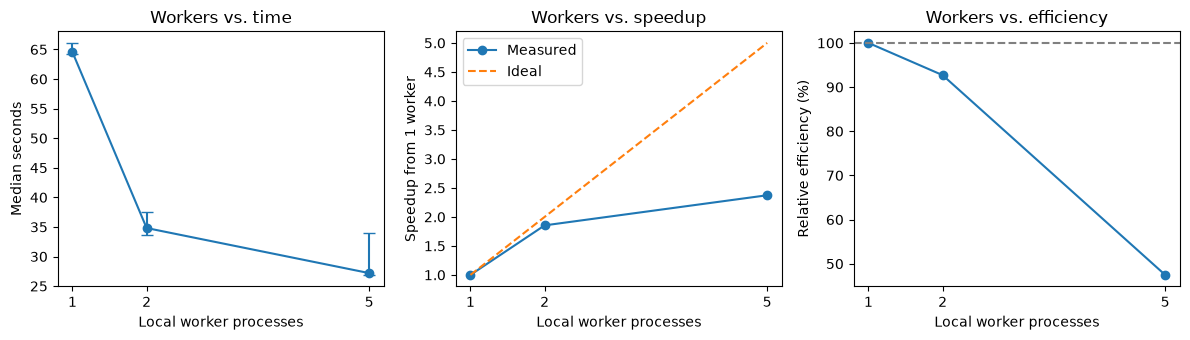

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
x = worker_summary.index
y = worker_summary.seconds
axes[0].errorbar(
    x, y, yerr=[y - worker_summary.min_s, worker_summary.max_s - y], fmt="o-", capsize=4
)
axes[0].set(ylabel="Median seconds", title="Workers vs. time")
axes[1].plot(x, worker_summary.speedup, "o-", label="Measured")
axes[1].plot(x, x, "--", label="Ideal")
axes[1].set(ylabel="Speedup from 1 worker", title="Workers vs. speedup")
axes[1].legend()
axes[2].plot(x, worker_summary.efficiency_pct, "o-")
axes[2].axhline(100, linestyle="--", color="gray")
axes[2].set(ylabel="Relative efficiency (%)", title="Workers vs. efficiency")
for ax in axes:
    ax.set_xlabel("Local worker processes")
    ax.set_xticks([1, 2, 5])
fig.tight_layout()
fig.savefig(RESULTS / "worker_scalability.png", dpi=160)
plt.show()

## 8. Configuration and cost

Local cloud cost is $0. Worker-seconds are a resource-use comparison, assuming equal hourly cost per worker; they are not a cloud invoice. This excludes any master charge, disks, startup, and idle time. Actual cloud cost cannot be inferred from this laptop run.

Task CPU share is CPU time / summed task elapsed time. It does not measure whole-laptop utilization. Workers share one disk and physical memory, so loopback shuffles and local contention differ from separate cloud machines.

In [ ]:
config = pd.DataFrame(
    {
        "workers": [1, 2, 5],
        "worker_task_slots": [2, 4, 10],
        "executor_heap_gib_each": [1.5, 1.5, 1.5],
        "driver_heap_gib": [2, 2, 2],
        "partitions": [PARTITIONS] * 3,
        "spark": [pyspark.__version__] * 3,
        "host": [platform.machine() + " / " + platform.system()] * 3,
        "physical_cpu_cores": [10] * 3,
        "physical_ram_gib": [16] * 3,
        "input_format": ["uncompressed CSV"] * 3,
        "output_format": ["Snappy Parquet"] * 3,
        "cloud_cost_usd": [0] * 3,
        "adaptive_enabled": [False] * 3,
        "constraint_propagation": [False] * 3,
        "input_split_mib": [32] * 3,
        "memory_fraction": [0.4] * 3,
    }
)
display(config)
config.to_csv(RESULTS / "configuration.csv", index=False)
display(
    worker_summary[
        [
            "seconds",
            "worker_seconds",
            "relative_worker_cost",
            "shuffle_mb",
            "spill_mb",
            "task_cpu_share_pct",
        ]
    ].round(3)
)

,workers,worker_task_slots,executor_heap_gib_each,driver_heap_gib,partitions,spark,host,physical_cpu_cores,physical_ram_gib,input_format,output_format,cloud_cost_usd,adaptive_enabled,constraint_propagation,input_split_mib,memory_fraction
0,1,2,1.5,2,64,4.0.1,arm64 / Darwin,10,16,uncompressed CSV,Snappy Parquet,0,False,False,32,0.4
1,2,4,1.5,2,64,4.0.1,arm64 / Darwin,10,16,uncompressed CSV,Snappy Parquet,0,False,False,32,0.4
2,5,10,1.5,2,64,4.0.1,arm64 / Darwin,10,16,uncompressed CSV,Snappy Parquet,0,False,False,32,0.4


,seconds,worker_seconds,relative_worker_cost,shuffle_mb,spill_mb,task_cpu_share_pct
workers,,,,,,
1,64.548,64.548,1.000,1008.971,54.962,97.976
2,34.815,69.630,1.079,1009.410,66.841,96.830
5,27.197,135.983,2.107,1008.809,74.494,73.809


## 9. Answers

The numbers below come from the recorded trials. Causes suggested by timing alone are possibilities; task/shuffle/spill evidence helps narrow them down.

In [ ]:
small = data_summary.iloc[0]
large = data_summary.iloc[-1]
data_growth = large.actual_mb / small.actual_mb
time_growth = large.seconds / small.seconds
gain = worker_summary.loc[2, "seconds"] / worker_summary.loc[5, "seconds"]
extra_cost = (
    worker_summary.loc[5, "worker_seconds"] / worker_summary.loc[2, "worker_seconds"]
)
saved = worker_summary.loc[2, "seconds"] - worker_summary.loc[5, "seconds"]
display(Markdown(f"""
1. **How does runtime scale with data?** Input grew {data_growth:.2f}× while median time grew {time_growth:.2f}×. Throughput rose from {small.mb_s:.2f} to {large.mb_s:.2f} MB/s. The same 64 output files and task setup cost more per MB on the small input. From 500 MB to 2 GB, time grew {large.seconds / data_summary.loc[500, 'seconds']:.2f}× for 4× the data, which is closer to linear.

2. **Does adding workers help?** Median times for 1, 2, and 5 workers were {worker_summary.loc[1, 'seconds']:.2f}, {worker_summary.loc[2, 'seconds']:.2f}, and {worker_summary.loc[5, 'seconds']:.2f} seconds. Five was fastest, but the 2→5-worker improvement was only {gain:.2f}× against an ideal 2.5×.

3. **Where are diminishing returns?** Relative efficiency fell from {worker_summary.loc[2, 'efficiency_pct']:.1f}% with 2 workers to {worker_summary.loc[5, 'efficiency_pct']:.1f}% with 5. Diminishing returns are clear at 5 workers. All processes still share the laptop's CPU, RAM, and SSD, and global statistics and stage boundaries add coordination.

4. **What do the Spark metrics show?** Every worker configuration ran {worker_summary.loc[2, 'tasks']:.0f} tasks and shuffled about {worker_summary.loc[2, 'shuffle_mb']:.0f} MB. Task disk spills were {worker_summary.loc[2, 'spill_mb']:.1f} MB with 2 workers and {worker_summary.loc[5, 'spill_mb']:.1f} MB with 5. Five workers used more summed task CPU time ({worker_summary.loc[5, 'cpu_seconds']:.1f} vs. {worker_summary.loc[2, 'cpu_seconds']:.1f} seconds), while task CPU share dropped from {worker_summary.loc[2, 'task_cpu_share_pct']:.1f}% to {worker_summary.loc[5, 'task_cpu_share_pct']:.1f}%. Extra overhead and waiting on shared resources are plausible; these counters do not isolate the cause.

5. **Is the extra compute worth it?** Five workers saved {saved:.2f} seconds over 2 workers but used {extra_cost:.2f}× the worker-seconds. Two workers gave a better balance of runtime and resource use here. Cloud charges were $0 for these local runs; actual Dataproc cost needs cloud rates and cloud measurements.

6. **What was unexpected?** The 2-worker/500 MB median was {data_summary.loc[500, 'seconds']:.2f} seconds inside the size study but {worker_summary.loc[2, 'seconds']:.2f} seconds in the fresh worker application. The size-study application had already processed larger inputs. JVM warm-up, file caching, or other host activity could affect the difference. To avoid mixing those histories, all worker comparisons use fresh applications with the same source-sized warm-up. This also shows why timings from different sessions should be compared carefully.
"""))


1. **How does runtime scale with data?** Input grew 19.92× while median time grew 12.93×. Throughput rose from 17.66 to 27.21 MB/s. The same 64 output files and task setup cost more per MB on the small input. From 500 MB to 2 GB, time grew 3.67× for 4× the data, which is closer to linear.

2. **Does adding workers help?** Median times for 1, 2, and 5 workers were 64.55, 34.81, and 27.20 seconds. Five was fastest, but the 2→5-worker improvement was only 1.28× against an ideal 2.5×.

3. **Where are diminishing returns?** Relative efficiency fell from 92.7% with 2 workers to 47.5% with 5. Diminishing returns are clear at 5 workers. All processes still share the laptop's CPU, RAM, and SSD, and global statistics and stage boundaries add coordination.

4. **What do the Spark metrics show?** Every worker configuration ran 320 tasks and shuffled about 1009 MB. Task disk spills were 66.8 MB with 2 workers and 74.5 MB with 5. Five workers used more summed task CPU time (159.4 vs. 119.5 seconds), while task CPU share dropped from 96.8% to 73.8%. Extra overhead and waiting on shared resources are plausible; these counters do not isolate the cause.

5. **Is the extra compute worth it?** Five workers saved 7.62 seconds over 2 workers but used 1.95× the worker-seconds. Two workers gave a better balance of runtime and resource use here. Cloud charges were $0 for these local runs; actual Dataproc cost needs cloud rates and cloud measurements.

6. **What was unexpected?** The 2-worker/500 MB median was 20.00 seconds inside the size study but 34.81 seconds in the fresh worker application. The size-study application had already processed larger inputs. JVM warm-up, file caching, or other host activity could affect the difference. To avoid mixing those histories, all worker comparisons use fresh applications with the same source-sized warm-up. This also shows why timings from different sessions should be compared carefully.


## 10. Checks and limitations

Replication increases processing work without adding new student information. It preserves repeated group patterns, so these results do not represent a growing, more diverse population. Repeated patterns may compress and cache more easily than new, diverse rows.

Floating-point aggregation order can cause tiny checksum differences. Row counts and group counts should match across worker configurations. The code checks those and compares summary values with the original source.

The experiments run on one laptop, in a fixed order, and OS caching, memory pressure, or thermal throttling can affect results. Three trials give a useful range, not a precise confidence interval. Results cannot establish Dataproc cost or network scaling.

In [ ]:
assert raw_workers.rows.nunique() == 1
assert raw_workers.groups.nunique() == 1
for r in raw_data.itertuples():
    copies = int(sizes.set_index("size_mb").loc[r.size_mb, "copies"])
    assert r.rows == source_rows * copies
np.testing.assert_allclose(raw_data.mean_score, source_mean, rtol=1e-9)
np.testing.assert_allclose(raw_workers.mean_score, source_mean, rtol=1e-9)
np.testing.assert_allclose(raw_data.feature_checksum, source_checksum, rtol=1e-8)
np.testing.assert_allclose(raw_workers.feature_checksum, source_checksum, rtol=1e-8)
display(
    raw_workers.groupby("workers")[["mean_score", "feature_checksum"]]
    .agg(["min", "max"])
    .round(6)
)
print("Row counts and summaries match the repeated source.")
print("Results saved to", RESULTS)

mean_score           feature_checksum            
               min       max              min         max
workers                                                  
1         67.25196  67.25196       393.376764  393.376764
2         67.25196  67.25196       393.376764  393.376764
5         67.25196  67.25196       393.376764  393.376764

Row counts and summaries match the repeated source.
Results saved to /Users/timwalewangko/Documents/git/comp644/hw5/results


## Sources / submission notes

- Reused project and dataset are linked at the top.
- [Spark standalone](https://spark.apache.org/docs/4.0.1/spark-standalone.html), [SQL functions](https://spark.apache.org/docs/4.0.1/api/python/reference/pyspark.sql/functions.html), and [monitoring](https://spark.apache.org/docs/4.0.1/monitoring.html).
- `results` contains every trial, median tables, configuration, and the five required plots in two figures. `.spark/events` holds Spark event logs; the live master UI is `http://127.0.0.1:8090` while a cluster runs.
- The PDF also asks for an 8–12 page report, a 12–15 minute presentation, and team contributions. This notebook supplies the experiments and analysis. The optional partition bonus is separate.